
## 02. Stratified Train-Test Split

### Objective

Separate the dataset into independent training and testing subsets while preserving the original diagnostic class distribution.

### Methodology

- **Splitting Strategy:** Stratified random sampling
- **Training Set:** 80%
- **Testing Set:** 20%
- **Random State:** 42
- **Stratification Variable:** Diagnosis

### Rationale

The WDBC dataset contains two diagnostic classes: Benign and Malignant.

Stratification maintains approximately the same class proportions in both subsets. This helps ensure that the testing set represents the original class distribution.

The test set will remain untouched during model training and preprocessing decisions.

### Split Results

| Dataset | Observations | Benign | Malignant |
|---|---:|---:|---:|
| Training | 455 | 285 | 170 |
| Testing | 114 | 72 | 42 |
| Total | 569 | 357 | 212 |

### Data Leakage Prevention

The training and testing observations are mutually exclusive.

Any learned preprocessing operations, including feature scaling and feature selection, will be fitted using training data only.

The testing set will be reserved for final model evaluation.


In [1]:

# ============================================================
# BREAST CANCER DETECTION
# MODEL DEVELOPMENT — DATA INITIALIZATION
# ============================================================

from pathlib import Path

import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split

# Project root
ROOT = Path.cwd()

if ROOT.name == "notebooks":
    ROOT = ROOT.parent

# Load validated dataset
DATA_PATH = ROOT / "data" / "processed" / "wdbc_cleaned.csv"

df = pd.read_csv(DATA_PATH)

# Remove identifier and separate target
X = df.drop(columns=["id", "diagnosis"])
y = df["diagnosis"].map({"B": 0, "M": 1})

# Dataset verification
assert X.shape == (569, 30), "Unexpected predictor dimensions."
assert y.notna().all(), "Target contains invalid labels."
assert X.isnull().sum().sum() == 0, "Missing predictor values detected."

print("MODEL DEVELOPMENT — DATA INITIALIZATION")
print("=" * 50)
print(f"Dataset shape       : {df.shape}")
print(f"Predictor shape     : {X.shape}")
print(f"Target shape        : {y.shape}")
print(f"Benign observations : {(y == 0).sum()}")
print(f"Malignant cases     : {(y == 1).sum()}")
print(f"Missing values      : {X.isnull().sum().sum()}")
print(f"Target mapping      : Benign=0, Malignant=1")
print("\nData initialization: PASSED")


MODEL DEVELOPMENT — DATA INITIALIZATION
Dataset shape       : (569, 32)
Predictor shape     : (569, 30)
Target shape        : (569,)
Benign observations : 357
Malignant cases     : 212
Missing values      : 0
Target mapping      : Benign=0, Malignant=1

Data initialization: PASSED


In [2]:

# ============================================================
# STEP 02 — STRATIFIED TRAIN-TEST SPLIT
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Split verification
print("STRATIFIED TRAIN-TEST SPLIT")
print("=" * 50)

print(f"Training observations : {len(X_train)}")
print(f"Testing observations  : {len(X_test)}")

print("\nTraining class distribution:")
print(
    y_train.map({0: "Benign", 1: "Malignant"})
    .value_counts()
)

print("\nTesting class distribution:")
print(
    y_test.map({0: "Benign", 1: "Malignant"})
    .value_counts()
)

print("\nTraining class proportions:")
print(y_train.value_counts(normalize=True).sort_index().round(4))

print("\nTesting class proportions:")
print(y_test.value_counts(normalize=True).sort_index().round(4))

assert len(X_train) == 455
assert len(X_test) == 114
assert set(X_train.index).isdisjoint(set(X_test.index))

print("\nTrain-test split: PASSED")


STRATIFIED TRAIN-TEST SPLIT
Training observations : 455
Testing observations  : 114

Training class distribution:
diagnosis
Benign       285
Malignant    170
Name: count, dtype: int64

Testing class distribution:
diagnosis
Benign       72
Malignant    42
Name: count, dtype: int64

Training class proportions:
diagnosis
0    0.6264
1    0.3736
Name: proportion, dtype: float64

Testing class proportions:
diagnosis
0    0.6316
1    0.3684
Name: proportion, dtype: float64

Train-test split: PASSED



## 03. Feature Preprocessing & Pipeline Design

### Objective

Prepare a consistent preprocessing architecture for evaluating multiple machine learning classifiers.

### Why Feature Scaling?

The WDBC dataset contains numerical predictors measured on different scales.

For example, area measurements have substantially larger numerical values than concavity measurements.

Standardization transforms each feature using its training-set mean and standard deviation.

### Preprocessing Strategy

- **StandardScaler:** Applied to scale-sensitive classification algorithms.
- **Random Forest:** Retains the original feature scales because tree-based models do not require standardization.
- **Pipeline Architecture:** Combines preprocessing and classification into a single estimator.

### Data Leakage Prevention

Each pipeline learns its scaling parameters exclusively from the data supplied to its `fit()` method.

During cross-validation, preprocessing is therefore refitted independently inside each training fold.

The held-out test set will not be used for fitting preprocessing parameters or selecting models.


In [3]:

# ============================================================
# STEP 03 — FEATURE PREPROCESSING & PIPELINE DESIGN
# ============================================================

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB

# Define candidate model pipelines
model_pipelines = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(
            max_iter=5000,
            random_state=42
        ))
    ]),

    "Support Vector Machine": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", SVC(
            kernel="rbf",
            probability=True,
            random_state=42
        ))
    ]),

    "K-Nearest Neighbors": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", KNeighborsClassifier(
            n_neighbors=5
        ))
    ]),

    "Random Forest": Pipeline([
        ("scaler", "passthrough"),
        ("classifier", RandomForestClassifier(
            n_estimators=300,
            random_state=42,
            n_jobs=-1
        ))
    ]),

    "Gaussian Naive Bayes": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", GaussianNB())
    ])
}

# Verify pipeline configuration
print("PREPROCESSING PIPELINE CONFIGURATION")
print("=" * 55)

for model_name, pipeline in model_pipelines.items():
    print(f"\n{model_name}")
    print(pipeline)

print("\nTotal candidate models:", len(model_pipelines))
print("Pipeline configuration: PASSED")


PREPROCESSING PIPELINE CONFIGURATION

Logistic Regression
Pipeline(steps=[('scaler', StandardScaler()),
                ('classifier',
                 LogisticRegression(max_iter=5000, random_state=42))])

Support Vector Machine
Pipeline(steps=[('scaler', StandardScaler()),
                ('classifier', SVC(probability=True, random_state=42))])

K-Nearest Neighbors
Pipeline(steps=[('scaler', StandardScaler()),
                ('classifier', KNeighborsClassifier())])

Random Forest
Pipeline(steps=[('scaler', 'passthrough'),
                ('classifier',
                 RandomForestClassifier(n_estimators=300, n_jobs=-1,
                                        random_state=42))])

Gaussian Naive Bayes
Pipeline(steps=[('scaler', StandardScaler()), ('classifier', GaussianNB())])

Total candidate models: 5
Pipeline configuration: PASSED



## 04. Baseline Model Evaluation Using Cross-Validation

### Objective

Establish a reliable baseline comparison of candidate classification algorithms before selecting a final model.

### Evaluation Strategy

- Cross-validation: Stratified 5-Fold
- Shuffle: Enabled
- Random State: 42
- Evaluation Dataset: Training set only
- Candidate Models: 5

### Evaluation Metrics

| Metric | Purpose |
|---|---|
| Accuracy | Overall classification correctness |
| Precision | Reliability of positive predictions |
| Recall | Proportion of malignant cases correctly identified |
| F1-score | Harmonic mean of precision and recall |
| ROC-AUC | Ability to distinguish between the two classes across thresholds |

### Why Stratified Cross-Validation?

Each fold approximately preserves the benign and malignant class proportions.

Every candidate model is evaluated across five different training-validation partitions. This provides a more stable estimate than relying on a single validation split.

### Model Selection Considerations

ROC-AUC will be used as the primary ranking metric for initial comparison. Recall, precision and F1-score will also be examined.

Because this is a breast cancer classification research project, false-negative predictions require particular attention.

The independent test set remains reserved for final evaluation after model selection.


In [ ]:

# STEP 04 — STRATIFIED 5-FOLD CROSS-VALIDATION

from sklearn.model_selection import StratifiedKFold, cross_validate

# Configure cross-validation
cv_strategy = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Define evaluation metrics
scoring_metrics = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

# Evaluate all candidate models
cv_results = {}

print("BASELINE MODEL EVALUATION")
print("=" * 65)

for model_name, pipeline in model_pipelines.items():

    scores = cross_validate(
        estimator=pipeline,
        X=X_train,
        y=y_train,
        cv=cv_strategy,
        scoring=scoring_metrics,
        return_train_score=False,
        n_jobs=1
    )

    cv_results[model_name] = {
        metric: scores[f"test_{metric}"].mean()
        for metric in scoring_metrics
    }

    cv_results[model_name].update({
        f"{metric}_std": scores[f"test_{metric}"].std()
        for metric in scoring_metrics
    })

    print(f"\nCompleted: {model_name}")

# Create comparison table
cv_results_df = pd.DataFrame(cv_results).T

# Sort by mean ROC-AUC
cv_results_df = cv_results_df.sort_values(
    by="roc_auc",
    ascending=False
)

# Display mean scores
mean_columns = [
    "accuracy",
    "precision",
    "recall",
    "f1",
    "roc_auc"
]

print("\nCROSS-VALIDATION PERFORMANCE")
print("=" * 65)

display(
    cv_results_df[mean_columns].round(4)
)

print("\nCross-validation completed successfully.")
print("Evaluation folds: 5")
print("Candidate models:", len(model_pipelines))


BASELINE MODEL EVALUATION

Completed: Logistic Regression

Completed: Support Vector Machine

Completed: K-Nearest Neighbors

Completed: Random Forest

Completed: Gaussian Naive Bayes

CROSS-VALIDATION PERFORMANCE


,accuracy,precision,recall,f1,roc_auc
Logistic Regression,0.9736,0.9771,0.9529,0.9640,0.9958
Support Vector Machine,0.9714,0.9769,0.9471,0.9610,0.9949
Random Forest,0.9604,0.9584,0.9353,0.9461,0.9880
K-Nearest Neighbors,0.9648,0.9875,0.9176,0.9510,0.9871
Gaussian Naive Bayes,0.9385,0.9247,0.9118,0.9170,0.9870



Cross-validation completed successfully.
Evaluation folds: 5
Candidate models: 5



## 05. Cross-Validation Stability Analysis

### Objective

Examine the consistency of candidate model performance across the five stratified validation folds.

### Methodology

For each evaluation metric, both the mean and standard deviation are examined.

- Mean: Average performance across five folds.
- Standard deviation: Variation in performance across folds.

A lower standard deviation indicates more consistent fold-level performance, although it does not independently establish model superiority.

### Interpretation

Model selection will consider both predictive performance and consistency.

Logistic Regression and Support Vector Machine are the leading candidates based on the initial mean performance results. Their stability will be examined before further optimization.


In [5]:

# STEP 05 — CROSS-VALIDATION STABILITY ANALYSIS

stability_metrics = [
    "accuracy",
    "precision",
    "recall",
    "f1",
    "roc_auc"
]

stability_table = pd.DataFrame(index=cv_results_df.index)

for metric in stability_metrics:
    stability_table[f"{metric}_mean"] = cv_results_df[metric]
    stability_table[f"{metric}_std"] = cv_results_df[
        f"{metric}_std"
    ]

print("CROSS-VALIDATION STABILITY REPORT")
print("=" * 75)

display(stability_table.round(4))

print("\nTOP TWO CANDIDATES")
print("=" * 75)

display(
    stability_table.loc[
        ["Logistic Regression", "Support Vector Machine"]
    ].round(4)
)

print("\nStability analysis generated successfully.")


CROSS-VALIDATION STABILITY REPORT


,accuracy_mean,accuracy_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,roc_auc_mean,roc_auc_std
Logistic Regression,0.9736,0.0149,0.9771,0.0280,0.9529,0.0399,0.9640,0.0207,0.9958,0.0047
Support Vector Machine,0.9714,0.0054,0.9769,0.0210,0.9471,0.0343,0.9610,0.0082,0.9949,0.0050
Random Forest,0.9604,0.0164,0.9584,0.0221,0.9353,0.0390,0.9461,0.0226,0.9880,0.0073
K-Nearest Neighbors,0.9648,0.0189,0.9875,0.0250,0.9176,0.0343,0.9510,0.0263,0.9871,0.0136
Gaussian Naive Bayes,0.9385,0.0256,0.9247,0.0461,0.9118,0.0492,0.9170,0.0342,0.9870,0.0071



TOP TWO CANDIDATES


,accuracy_mean,accuracy_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,roc_auc_mean,roc_auc_std
Logistic Regression,0.9736,0.0149,0.9771,0.028,0.9529,0.0399,0.964,0.0207,0.9958,0.0047
Support Vector Machine,0.9714,0.0054,0.9769,0.021,0.9471,0.0343,0.961,0.0082,0.9949,0.0050



Stability analysis generated successfully.



## 06. Hyperparameter Optimization

### Objective

Optimize the two leading baseline classifiers to investigate whether their predictive performance can be improved through systematic hyperparameter search.

### Candidate Models

1. Logistic Regression
2. Support Vector Machine with RBF kernel

### Optimization Method

- Search Strategy: GridSearchCV
- Cross-Validation: Stratified 5-Fold
- Primary Selection Metric: ROC-AUC
- Additional Metrics: Accuracy, Precision, Recall and F1-score
- Data Used: Training set only

### Hyperparameters

**Logistic Regression**
- C: Regularization strength.
- Penalty: L1 and L2 regularization.
- Class Weight: None or balanced.

**Support Vector Machine**
- C: Regularization strength.
- Gamma: RBF kernel influence.
- Class Weight: None or balanced.

### Leakage Prevention

Each candidate configuration is evaluated through a pipeline. Scaling is fitted independently within each training fold.

The independent test set remains untouched throughout optimization.


In [6]:

# STEP 06 — HYPERPARAMETER OPTIMIZATION


from sklearn.model_selection import GridSearchCV

# Hyperparameter search spaces
param_grids = {
    "Logistic Regression": {
        "classifier__C": [0.01, 0.1, 1, 10, 100],
        "classifier__penalty": ["l1", "l2"],
        "classifier__solver": ["liblinear"],
        "classifier__class_weight": [None, "balanced"]
    },

    "Support Vector Machine": {
        "classifier__C": [0.1, 1, 10, 100],
        "classifier__gamma": ["scale", 0.001, 0.01, 0.1],
        "classifier__class_weight": [None, "balanced"]
    }
}

# Optimize both leading models
optimized_models = {}
optimization_results = {}

for model_name in ["Logistic Regression", "Support Vector Machine"]:

    print(f"\nOptimizing: {model_name}")
    print("-" * 55)

    search = GridSearchCV(
        estimator=model_pipelines[model_name],
        param_grid=param_grids[model_name],
        scoring={
            "roc_auc": "roc_auc",
            "recall": "recall",
            "precision": "precision",
            "f1": "f1",
            "accuracy": "accuracy"
        },
        refit="roc_auc",
        cv=cv_strategy,
        n_jobs=-1,
        return_train_score=False,
        verbose=0
    )

    search.fit(X_train, y_train)

    optimized_models[model_name] = search.best_estimator_

    best_index = search.best_index_

    optimization_results[model_name] = {
        "best_cv_roc_auc": search.best_score_,
        "best_cv_recall": search.cv_results_[
            "mean_test_recall"
        ][best_index],
        "best_cv_precision": search.cv_results_[
            "mean_test_precision"
        ][best_index],
        "best_cv_f1": search.cv_results_[
            "mean_test_f1"
        ][best_index],
        "best_cv_accuracy": search.cv_results_[
            "mean_test_accuracy"
        ][best_index],
        "best_parameters": search.best_params_
    }

    print("Best ROC-AUC:", round(search.best_score_, 4))
    print("Best parameters:", search.best_params_)

# Create optimization comparison
optimization_df = pd.DataFrame({
    model: {
        metric: value
        for metric, value in results.items()
        if metric != "best_parameters"
    }
    for model, results in optimization_results.items()
}).T

print("\nOPTIMIZED MODEL COMPARISON")
print("=" * 65)

display(optimization_df.round(4))

print("\nHyperparameter optimization completed.")



Optimizing: Logistic Regression
-------------------------------------------------------
Best ROC-AUC: 0.9959
Best parameters: {'classifier__C': 1, 'classifier__class_weight': None, 'classifier__penalty': 'l1', 'classifier__solver': 'liblinear'}

Optimizing: Support Vector Machine
-------------------------------------------------------
Best ROC-AUC: 0.996
Best parameters: {'classifier__C': 100, 'classifier__class_weight': None, 'classifier__gamma': 0.001}

OPTIMIZED MODEL COMPARISON


,best_cv_roc_auc,best_cv_recall,best_cv_precision,best_cv_f1,best_cv_accuracy
Logistic Regression,0.9959,0.9471,0.9822,0.9638,0.9736
Support Vector Machine,0.9960,0.9529,0.9775,0.9640,0.9736



Hyperparameter optimization completed.



## 07. Independent Test-Set Evaluation

### Objective

Evaluate the optimized candidate classifiers on the independent test set to assess their generalization performance on previously unseen observations.

### Selected Candidates

- Optimized Support Vector Machine (primary candidate).
- Optimized Logistic Regression (benchmark candidate).

### Evaluation Metrics

- Accuracy
- Precision
- Recall (Sensitivity)
- Specificity
- F1-score
- ROC-AUC
- Confusion Matrix

The malignant diagnosis is treated as the positive class.

### Evaluation Protocol

Both optimized pipelines were selected using training-set cross-validation.

The test set has not been used for preprocessing, hyperparameter optimization or model fitting.

The default classification threshold of 0.50 is retained for this initial evaluation. Threshold optimization, if performed, will use training-only validation predictions.


In [7]:

# STEP 07 — INDEPENDENT TEST-SET EVALUATION

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

test_candidates = {
    "Optimized Logistic Regression": optimized_models[
        "Logistic Regression"
    ],
    "Optimized SVM": optimized_models[
        "Support Vector Machine"
    ]
}

test_results = {}
test_predictions = {}
test_probabilities = {}

for model_name, model in test_candidates.items():

    # Predict class labels and malignant probabilities
    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    test_predictions[model_name] = predictions
    test_probabilities[model_name] = probabilities

    tn, fp, fn, tp = confusion_matrix(
        y_test,
        predictions,
        labels=[0, 1]
    ).ravel()

    specificity = tn / (tn + fp) if (tn + fp) else 0

    test_results[model_name] = {
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "Specificity": specificity,
        "F1-score": f1_score(
            y_test, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, probabilities),
        "True Negatives": tn,
        "False Positives": fp,
        "False Negatives": fn,
        "True Positives": tp
    }

    print(f"\n{model_name}")
    print("=" * 60)
    print(classification_report(
        y_test,
        predictions,
        labels=[0, 1],
        target_names=["Benign", "Malignant"],
        digits=4,
        zero_division=0
    ))

# Comparison table
test_results_df = pd.DataFrame(test_results).T

print("\nINDEPENDENT TEST-SET COMPARISON")
print("=" * 75)
display(test_results_df.round(4))

print("\nTest observations evaluated:", len(X_test))
print("Test-set evaluation completed.")



Optimized Logistic Regression
              precision    recall  f1-score   support

      Benign     0.9726    0.9861    0.9793        72
   Malignant     0.9756    0.9524    0.9639        42

    accuracy                         0.9737       114
   macro avg     0.9741    0.9692    0.9716       114
weighted avg     0.9737    0.9737    0.9736       114


Optimized SVM
              precision    recall  f1-score   support

      Benign     0.9600    1.0000    0.9796        72
   Malignant     1.0000    0.9286    0.9630        42

    accuracy                         0.9737       114
   macro avg     0.9800    0.9643    0.9713       114
weighted avg     0.9747    0.9737    0.9735       114


INDEPENDENT TEST-SET COMPARISON


,Accuracy,Precision,Recall,Specificity,F1-score,ROC-AUC,True Negatives,False Positives,False Negatives,True Positives
Optimized Logistic Regression,0.9737,0.9756,0.9524,0.9861,0.9639,0.9964,71.0,1.0,2.0,40.0
Optimized SVM,0.9737,1.0000,0.9286,1.0000,0.9630,0.9957,72.0,0.0,3.0,39.0



Test observations evaluated: 114
Test-set evaluation completed.



## 08. Classification Performance Visualization

### Objective

Visualize the classification outcomes and discrimination capability of the optimized candidate models.

### Confusion Matrix

The confusion matrix provides a detailed breakdown of:
- True Positives
- False Positives
- True Negatives
- False Negatives

### ROC Curve

The Receiver Operating Characteristic (ROC) curve evaluates the trade-off between the true positive rate and false positive rate across classification thresholds.

The Area Under the Curve (ROC-AUC) summarizes the model's ranking ability.

### Interpretation

Both optimized models demonstrated strong performance on the independent test set.

Logistic Regression achieved higher malignant recall and ROC-AUC, while SVM achieved higher malignant precision and specificity.

These visualizations document the observed test-set performance. The test set will not be used for further model tuning.


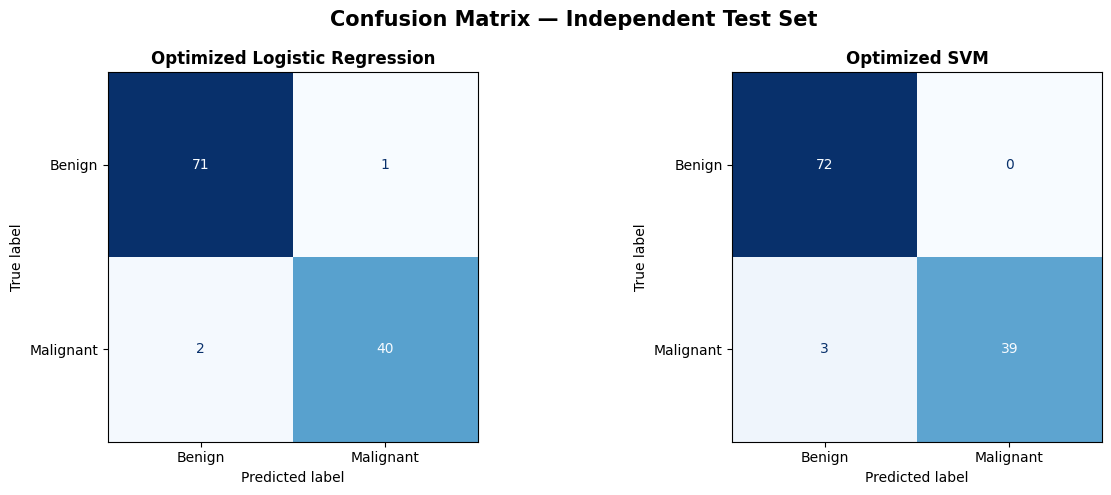

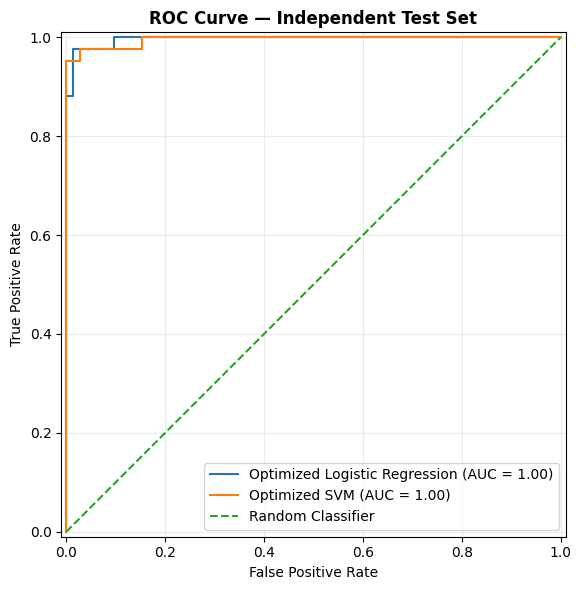

EVALUATION VISUALIZATION EXPORT
Confusion matrices: True
ROC curve: True


In [8]:

# ============================================================
# STEP 08 — CONFUSION MATRIX & ROC VISUALIZATION
# ============================================================

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay

# 1. Confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, (model_name, predictions) in zip(
    axes, test_predictions.items()
):
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predictions,
        labels=[0, 1],
        display_labels=["Benign", "Malignant"],
        cmap="Blues",
        colorbar=False,
        ax=ax
    )
    ax.set_title(model_name, fontweight="bold")

fig.suptitle(
    "Confusion Matrix — Independent Test Set",
    fontsize=15,
    fontweight="bold"
)
fig.tight_layout()

confusion_output = ROOT / "outputs" / "eda" / "confusion_matrices.png"
fig.savefig(
    confusion_output,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)
plt.show()
plt.close(fig)


# 2. ROC curves
fig, ax = plt.subplots(figsize=(8, 6))

for model_name, probabilities in test_probabilities.items():
    RocCurveDisplay.from_predictions(
        y_test,
        probabilities,
        name=model_name,
        ax=ax
    )

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

ax.set_title(
    "ROC Curve — Independent Test Set",
    fontweight="bold"
)
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.legend(loc="lower right")
ax.grid(alpha=0.25)

fig.tight_layout()

roc_output = ROOT / "outputs" / "eda" / "roc_curve_comparison.png"
fig.savefig(
    roc_output,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)
plt.show()
plt.close(fig)

print("EVALUATION VISUALIZATION EXPORT")
print("=" * 50)
print("Confusion matrices:", confusion_output.exists())
print("ROC curve:", roc_output.exists())


In [9]:
from pathlib import Path
import shutil
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

# Define directories
EDA_DIR = ROOT / "outputs" / "eda"
EVALUATION_DIR = ROOT / "outputs" / "model_evaluation"

# Create destination directory
EVALUATION_DIR.mkdir(parents=True, exist_ok=True)

# Define source and destination files
files_to_move = [
    "confusion_matrices.png",
    "roc_curve_comparison.png"
]

# Move existing exported visualizations
for filename in files_to_move:
    source = EDA_DIR / filename
    destination = EVALUATION_DIR / filename

    if source.exists():
        shutil.move(str(source), str(destination))
        print(f"MOVED: {filename}")

    elif destination.exists():
        print(f"ALREADY IN DESTINATION: {filename}")

    else:
        print(f"NOT FOUND: {filename}")

# Verify saved files
print("\n" + "=" * 55)
print("MODEL EVALUATION EXPORT VERIFICATION")
print("=" * 55)

for filename in files_to_move:
    file_path = EVALUATION_DIR / filename

    if file_path.exists():
        image = mpimg.imread(file_path)
        print(f"SUCCESS: {filename}")
        print(f"Location: {file_path.relative_to(ROOT)}")
        print(f"Image dimensions: {image.shape}")
        print(f"File size: {file_path.stat().st_size:,} bytes\n")
    else:
        print(f"FAILED: {filename} not found.\n")

print("Evaluation visualization organization completed.")

MOVED: confusion_matrices.png
MOVED: roc_curve_comparison.png

MODEL EVALUATION EXPORT VERIFICATION
SUCCESS: confusion_matrices.png
Location: outputs\model_evaluation\confusion_matrices.png
Image dimensions: (1485, 3334, 4)
File size: 93,259 bytes

SUCCESS: roc_curve_comparison.png
Location: outputs\model_evaluation\roc_curve_comparison.png
Image dimensions: (1765, 1745, 4)
File size: 111,490 bytes

Evaluation visualization organization completed.


### 8. Evaluation Visualizations

Confusion matrices and ROC curves were generated to compare the optimized Logistic Regression and Support Vector Machine (SVM) models on the independent test set.

**Confusion Matrix Analysis**

Logistic Regression correctly classified 71 benign and 40 malignant cases, with 1 false positive and 2 false negatives. SVM correctly classified 72 benign and 39 malignant cases, with 0 false positives and 3 false negatives.

Logistic Regression detected one additional malignant case compared with SVM. SVM, however, produced no false-positive predictions.

**ROC Curve Analysis**

Both models demonstrated excellent discrimination on the independent test set. Logistic Regression achieved an ROC-AUC of 0.9964, while SVM achieved 0.9957.

**Conclusion**

Both optimized models performed strongly. Logistic Regression is provisionally preferred because it achieved higher malignant-case recall, a slightly higher F1-score, and a slightly higher ROC-AUC. SVM achieved higher malignant-case precision and specificity.

These results are based on a single independent test set of 114 observations. They should not be interpreted as evidence of clinical readiness. Further external validation would be necessary before any real-world medical use.